# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import mBrickKilnDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/m_brick_kiln/data/",
    "csv_file": "./data/m_brick_kiln/default_partition.json",
    "mode": "train"
}
dataset = mBrickKilnDataset(dataset_config)
print(len(dataset))

15063


## Show images from the dataset

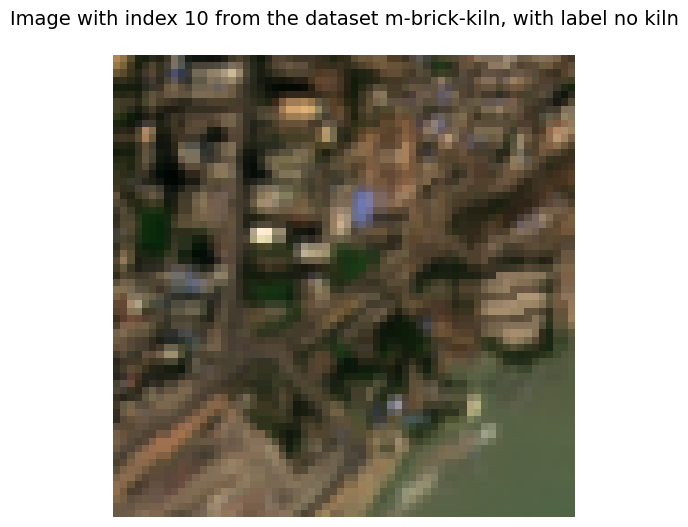

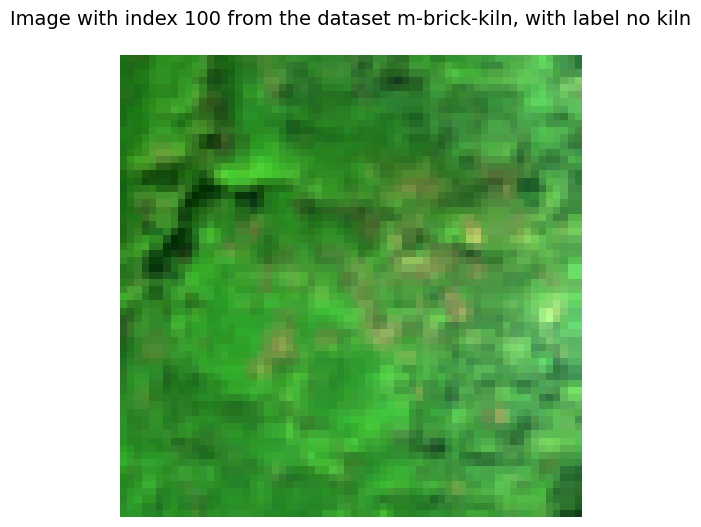

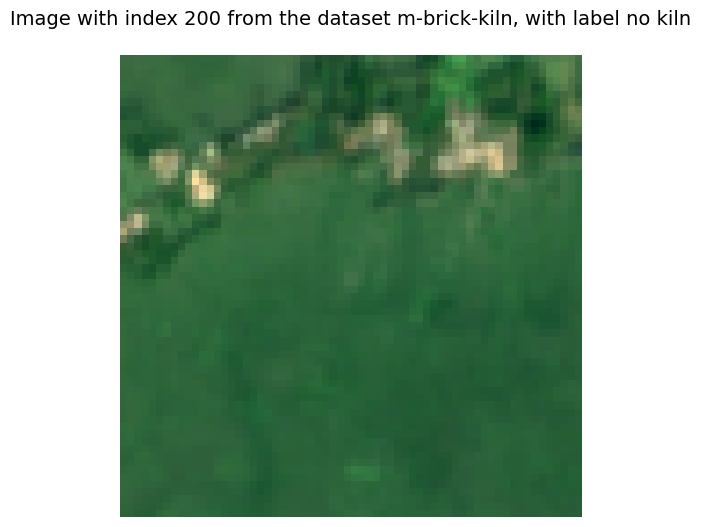

In [29]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(100)
fig3 = dataset.show_image(200)

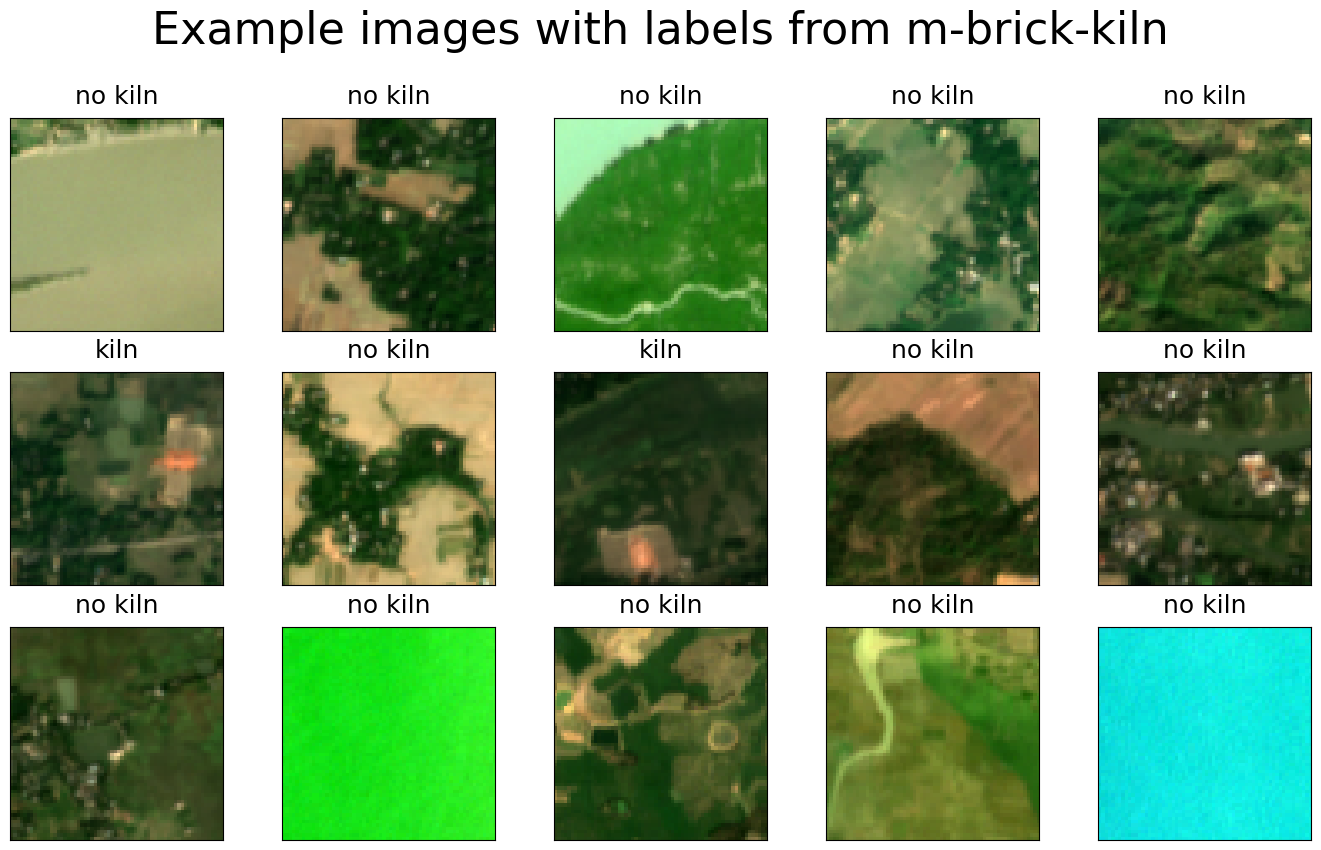

In [30]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [8]:
dataset.data_distribution_table()

,Label,Count
0,no kiln,10000
1,kiln,5063


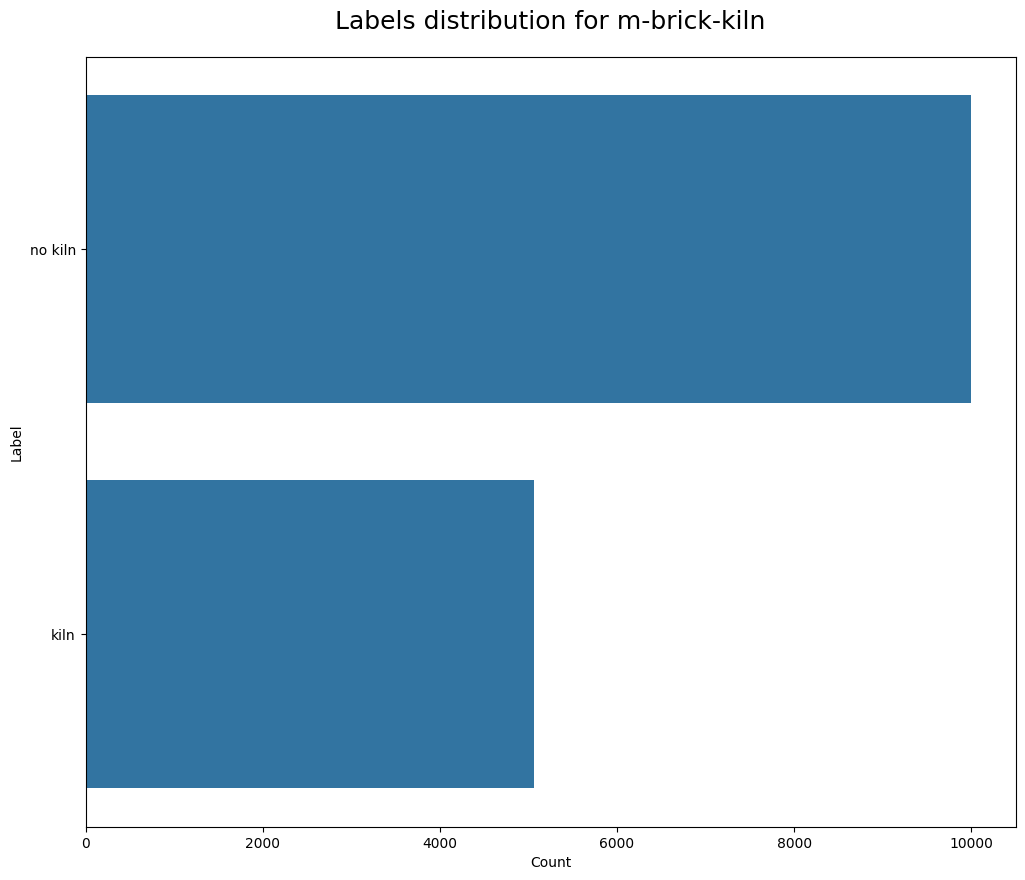

In [9]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/m_brick_kiln/data/",
    "csv_file": "./data/m_brick_kiln/default_partition.json",
    "mode": "train"
}

train_dataset = mBrickKilnDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/m_brick_kiln/data/",
    "csv_file": "./data/m_brick_kiln/default_partition.json",
    "mode": "valid",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = mBrickKilnDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(15063, 999)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/m_brick_kiln/"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2026-05-04 08:06:32,121 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2026-05-04 08:06:32,495 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [13]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2026-05-04 08:06:32,561 INFO Starting training.
training: 100%|██████████| 471/471 [01:56<00:00,  4.03it/s]
2026-05-04 08:08:29,663 INFO epoch: 1, time: 117, loss:  0.14930
testing on train set: 100%|██████████| 471/471 [00:41<00:00, 11.37it/s]
2026-05-04 08:09:13,824 INFO Accuracy:0.9522007568213503, Precision Micro:0.9522007568213503, Precision Macro:0.9401491472439071, Precision Weighted:0.9547000879345007, Precision per Class:[0.9845447 0.8957536], Recall Micro:0.9522007568213503, Recall Macro:0.9567841595891764, Recall Weighted:0.9522007568213504, Recall per Class:[0.9428     0.97076832], F1_score Micro:0.9522007568213497, F1_score Macro:0.9474869121101953, F1_score Weighted:0.9526436263444009, F1_score per Class:[0.96322027 0.93175355]
testing on validation set: 100%|██████████| 32/32 [00:03<00:00, 10.20it/s]
2026-05-04 08:09:16,970 INFO Accuracy:0.934934934934935, Precision Micro:0.934934934934935, Precision Macro:0.9197309074229798, Precision Weighted:0.9407086162685888, Precis

0.10418939084598111

## Test the model

In [ ]:
test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/m_brick_kiln/data/",
    "csv_file": "./data/m_brick_kiln/default_partition.json",
    "mode": "test",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = mBrickKilnDataset(test_dataset_config)
model_path = "./data/experiments/m_brick_kiln/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2026-05-04 08:39:48,394 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/m_brick_kiln/checkpoint.pth.tar
2026-05-04 08:39:48,748 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/m_brick_kiln/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 63/63 [00:03<00:00, 19.21it/s]


[{'Accuracy': 0.970970970970971},
 {'Precision Micro': 0.970970970970971,
  'Precision Macro': 0.969849838951141,
  'Precision Weighted': 0.9709249420903914,
  'Precision per Class': array([0.97313433, 0.96656535])},
 {'Recall Micro': 0.970970970970971,
  'Recall Macro': 0.9649186597716009,
  'Recall Weighted': 0.9709709709709708,
  'Recall per Class': array([0.98340875, 0.94642857])},
 {'F1_score Micro': 0.9709709709709705,
  'F1_score Macro': 0.9673177692919463,
  'F1_score Weighted': 0.970894406863925,
  'F1_score per Class': array([0.97824456, 0.95639098])}]

## Predictions

2026-05-04 08:40:06,452 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/m_brick_kiln/checkpoint.pth.tar
2026-05-04 08:40:06,778 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/m_brick_kiln/checkpoint.pth.tar at epoch 11


999


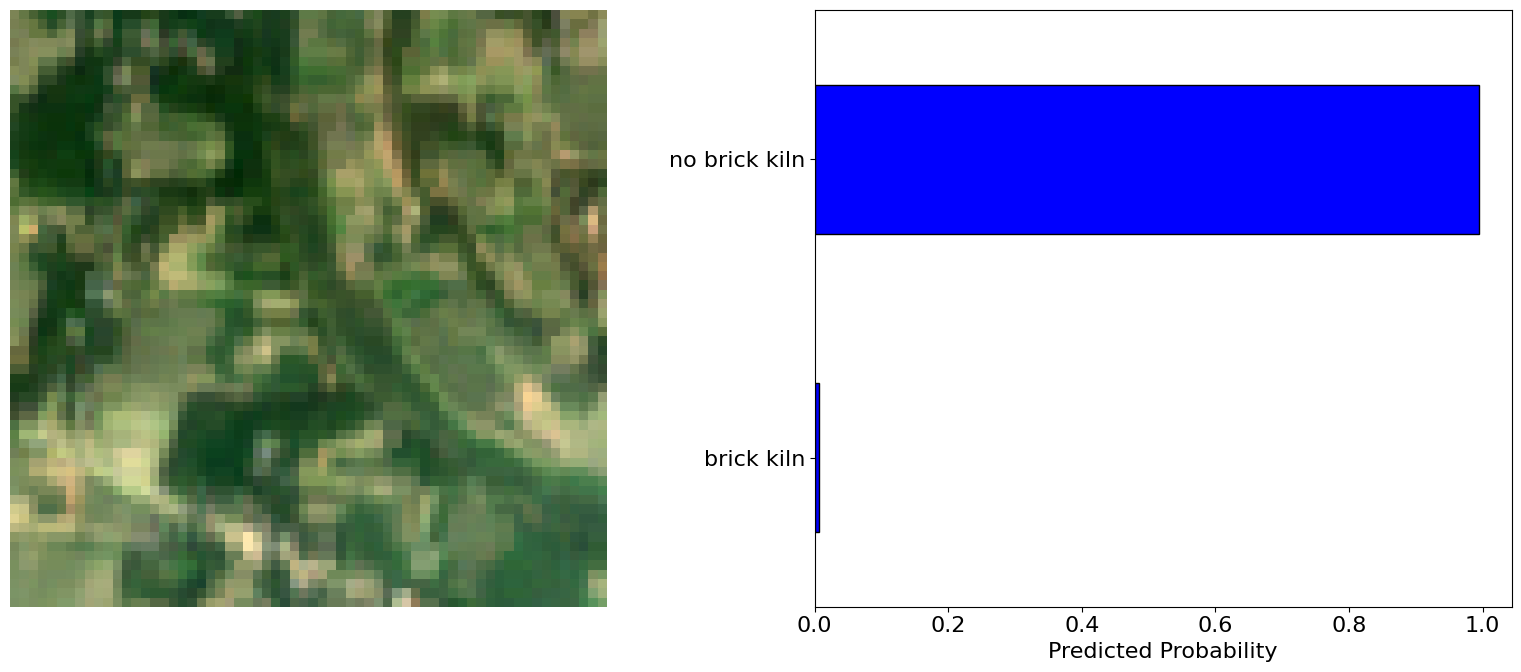

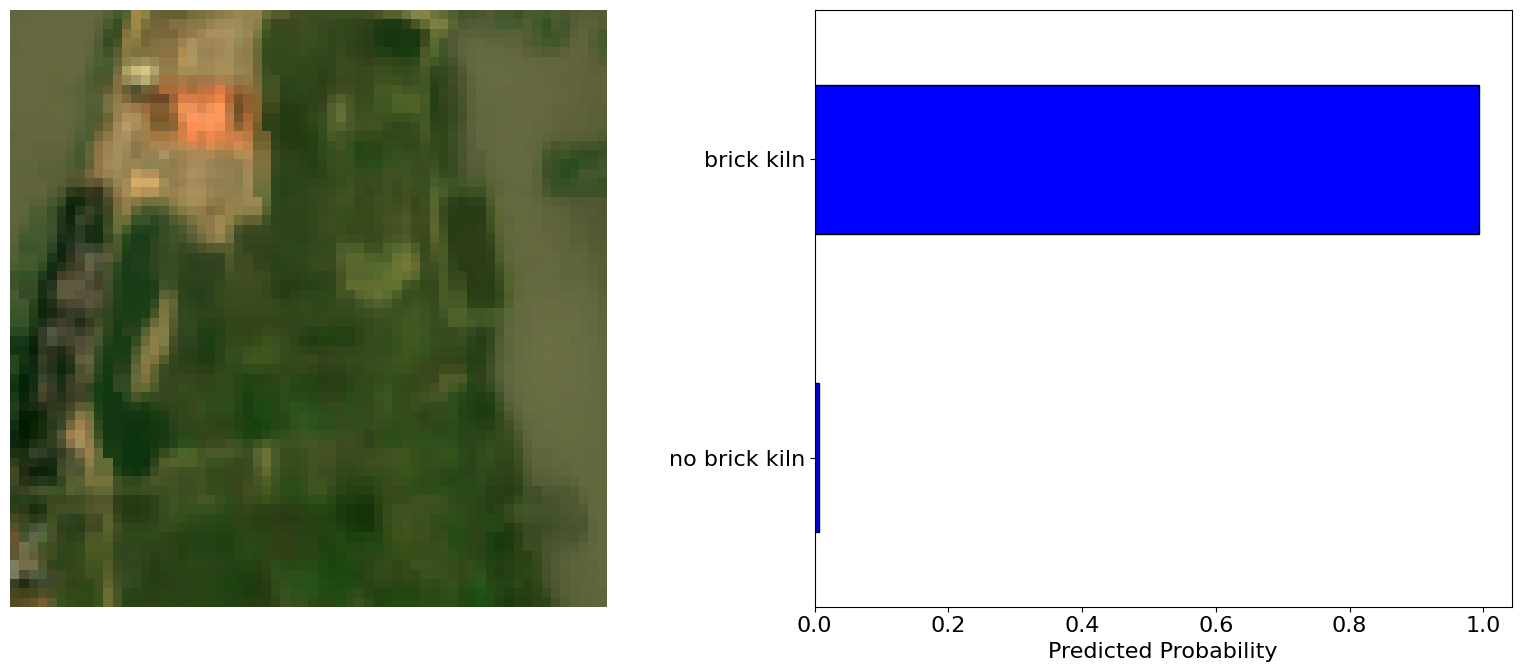

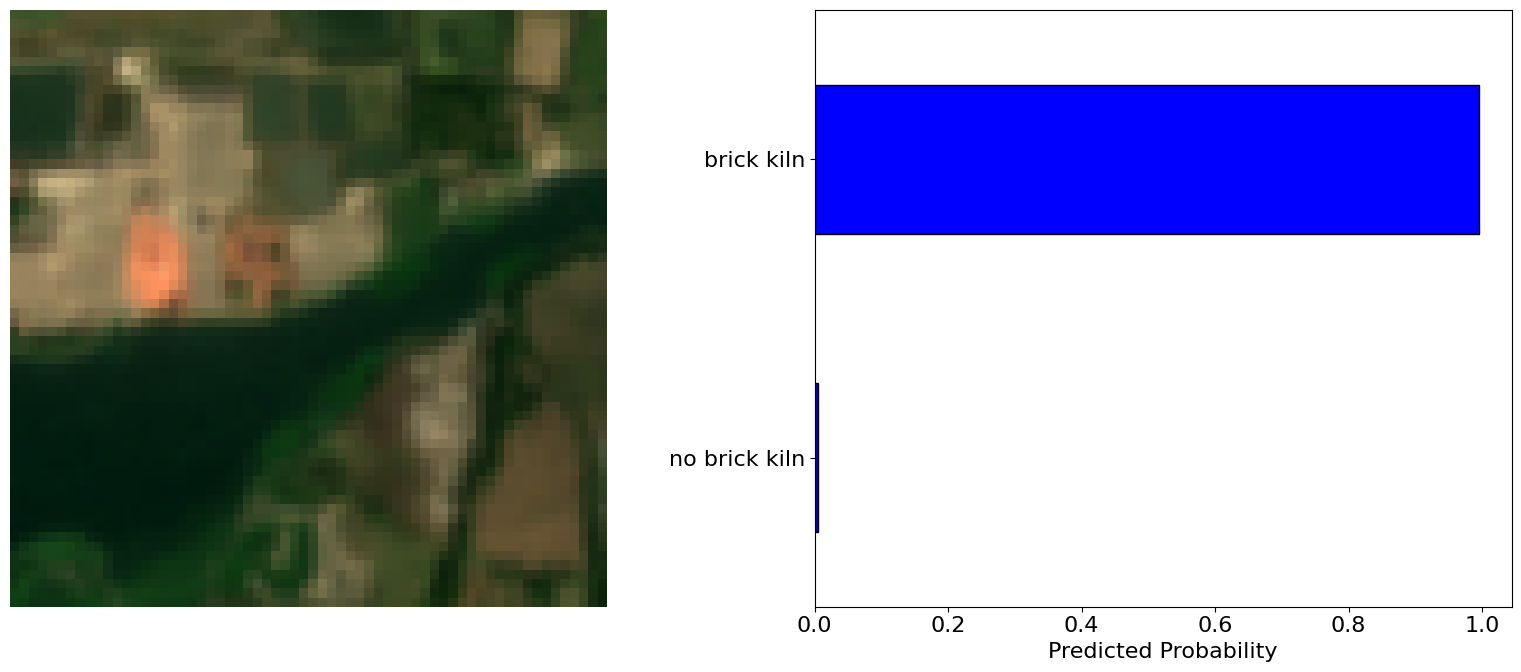

In [ ]:
labels = ["no brick kiln","brick kiln"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/m_brick_kiln/checkpoint.pth.tar"
model.load_model(model_path)

test_dataset_config = {
    "data_dir": "./data/m_brick_kiln/data/",
    "csv_file": "./data/m_brick_kiln/default_partition.json",
    "mode": "test"
}
test_dataset = mBrickKilnDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_image(image, labels, transform)

image = test_dataset[100][0]
fig = model.predict_image(image, labels, transform)